## Experiment with Missing Data

A second version of the original hockey dataset was generated separately to maintain the raw dataset.

Cells containing non-missing data from the input features in `GF` (Goals For) and `GA` (Goals Against) were randomly chosen for about 5% of the cells and converted into `NaN`.

A fixed random seed was used in order to get repeatable results. Random sampling was done without replacement.

`Wins` and `Win %` columns were exempted from generating any missing values, as per project guidelines.

The original missing value of 224 values in `OT Losses` column was retained.

The updated dataset was stored as `data/hockey_teams_missing.csv`, while the original `data/hockey_teams_raw.csv` was kept intact.

**Code Implementation:** `src/preprocessing.py`

In [1]:
import pandas as pd

raw = pd.read_csv("../data/hockey_teams_raw.csv")
modified = pd.read_csv("../data/hockey_teams_missing.csv")

print("Original missing values:")
print(raw.isnull().sum())

print("\nModified missing values:")
print(modified.isnull().sum())

print("\nNew missing values:")
print(
    modified[raw.columns].isnull().sum()
    - raw.isnull().sum()
)

Original missing values:
Team Name         0
Year              0
Wins              0
Losses            0
OT Losses       224
Win %             0
GF                0
GA                0
+/-               0
collected_at      0
dtype: int64

Modified missing values:
Team Name         0
Year              0
Wins              0
Losses            0
OT Losses       224
Win %             0
GF               28
GA               30
+/-               0
collected_at      0
Team_Status       0
dtype: int64

New missing values:
Team Name        0
Year             0
Wins             0
Losses           0
OT Losses        0
Win %            0
GF              28
GA              30
+/-              0
collected_at     0
dtype: int64


## Data Collection Evidence

The original hockey dataset was collected by Person A
from Scrape This Site as part of our shared project.

This notebook uses the working dataset derived from
the original raw dataset.

The SHA-256 fingerprint is calculated to verify the
integrity and authenticity of the original dataset.
The complete data collection log is available in
the web scraping notebook (project.ipynb).

In [2]:
import hashlib
import pandas as pd

raw_path = "../data/hockey_teams_raw.csv"

with open(raw_path, "rb") as f:
    fingerprint = hashlib.sha256(f.read()).hexdigest()

raw_df = pd.read_csv(raw_path)

expected_fingerprint = "1985bac902d455f29c40365373b8b44342819075c646e950bfa9b72e7e10cf85"

print("=" * 60)
print("DATA COLLECTION LOG AND VERIFICATION")
print("=" * 60)

print("Team Roll Numbers      : 25L-0012, 25L-2545")
print("Source URL             : https://www.scrapethissite.com/pages/forms/")
print("Collection Start Time  : 2026-11-15 13:05:49")
print("Collection End Time    : 2026-11-15 13:06:18")
print("Total Requests / Pages : 7")
print("Raw Dataset Filename   : hockey_teams_raw.csv")
print("Raw Dataset Shape      :", raw_df.shape)
print("Total Rows Collected   :", len(raw_df))
print("Timestamp Column Exists:", "collected_at" in raw_df.columns)
print("SHA-256 Fingerprint    :", fingerprint)
print("Fingerprint Matches    :", fingerprint == expected_fingerprint)
print("=" * 60)

DATA COLLECTION LOG AND VERIFICATION
Team Roll Numbers      : 25L-0012, 25L-2545
Source URL             : https://www.scrapethissite.com/pages/forms/
Collection Start Time  : 2026-11-15 13:05:49
Collection End Time    : 2026-11-15 13:06:18
Total Requests / Pages : 7
Raw Dataset Filename   : hockey_teams_raw.csv
Raw Dataset Shape      : (582, 10)
Total Rows Collected   : 582
Timestamp Column Exists: True
SHA-256 Fingerprint    : 1985bac902d455f29c40365373b8b44342819075c646e950bfa9b72e7e10cf85
Fingerprint Matches    : True


### Data Collection Log and Integrity Verification

The original dataset was collected by Person A on
November 15, 2026, from the Scrape This Site website
using seven page requests.

A total of 582 records and 10 columns were collected.

The collection details are taken from the original
data collection log in project.ipynb.

The SHA-256 fingerprint matches the original fingerprint,
confirming that the raw dataset remains unchanged.

The classification notebook uses a separate working
dataset derived from this original dataset.

## Data Cleaning and Exploratory Analysis

In [3]:
import pandas as pd

df = pd.read_csv("../data/hockey_teams_missing.csv")
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
print(df.describe().to_string())
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print("\nMissing values:")
print(missing_summary.to_string())

print("\nExact duplicate rows:", df.duplicated().sum())

Dataset shape: (582, 11)

Data types:
Team Name           str
Year              int64
Wins              int64
Losses            int64
OT Losses       float64
Win %           float64
GF              float64
GA              float64
+/-               int64
collected_at        str
Team_Status       int64
dtype: object

Summary statistics:
              Year        Wins      Losses   OT Losses       Win %          GF          GA         +/-  Team_Status
count   582.000000  582.000000  582.000000  358.000000  582.000000  554.000000  552.000000  582.000000   582.000000
mean   2000.907216   36.943299   32.353952    7.460894    0.458519  234.456679  234.186594    0.000000     0.398625
std       6.330674    8.926081    8.411439    3.610191    0.102237   40.885972   42.057945   45.277458     0.490037
min    1990.000000    9.000000   11.000000    0.000000    0.119000  115.000000  119.000000 -196.000000     0.000000
25%    1996.000000   31.000000   27.000000    5.000000    0.390000  211.000000  207

### Data Quality Inspection – Analysis

The loaded dataset comprises 582 rows and 11 columns and captures historical seasons of teams from the year 1990.

The presence of missing values was detected in the features GF (4.81%) and GA (5.15%). They were added during the experiment with missing data. The OT Losses feature has 224 missing values (38.49%) already.

There are no duplicate rows to handle.

The numerical description reveals a high variation in team performance. The average value of the Wins feature is around 36.94, and the Winning % feature is approximately 0.459.

The target feature has approximately 39.86% of winning seasons and 60.14% non-winning seasons.

Missing values will be addressed using the preprocessing pipeline that will be fit only on the training data.

## Numerical Distributions, Skewness and Outlier Analysis

Skewness:
Year   -0.032
GF      0.257
GA      0.387
+/-    -0.578


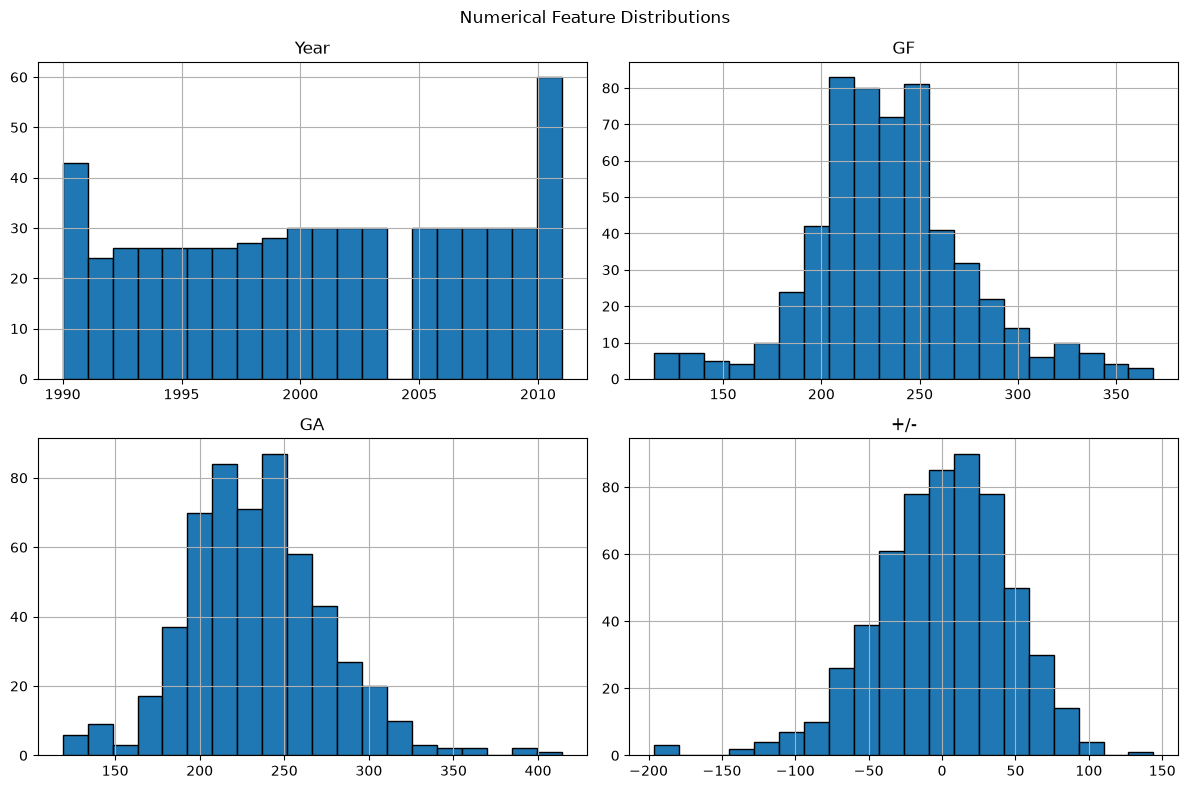

<Figure size 1200x600 with 0 Axes>

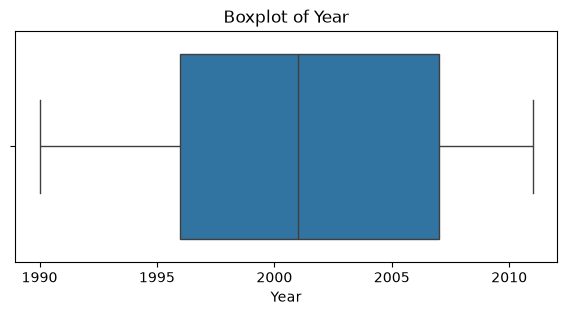

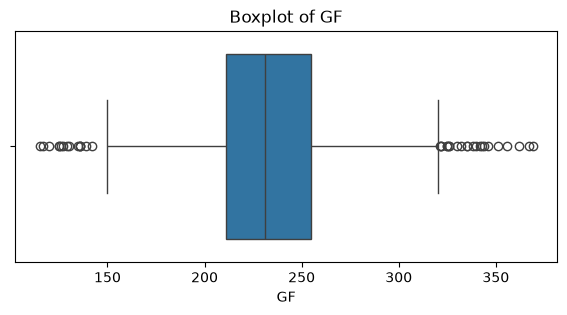

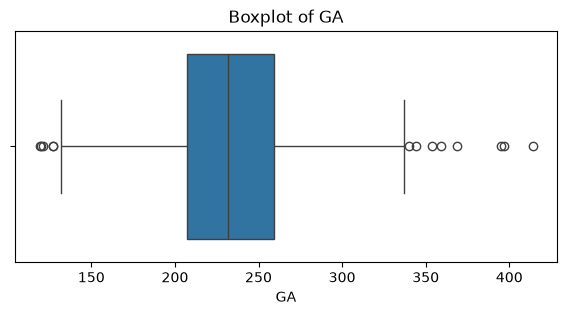

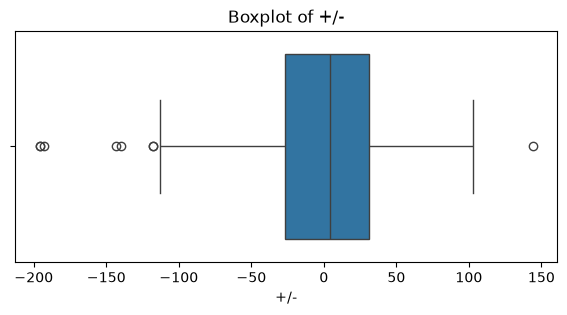

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/hockey_teams_missing.csv")

# Numerical features relevant to classification
numeric_cols = ["Year", "GF", "GA", "+/-"]

# Calculate skewness
print("Skewness:")
print(df[numeric_cols].skew().round(3).to_string())

# Create histograms
df[numeric_cols].hist(
    bins=20,
    figsize=(12, 8), #Sets the overall figure dimensions to 12 inches wide and 8 inches tall.
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout() #Adjusts spacing so that chart titles, axis labels and plots are less likely to overlap.
plt.show()
plt.figure(figsize=(12, 6))

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


### Numerical Feature Distribution

The skewness, histograms and boxplots are used to understand the distribution of numerical features and identify possible outliers.

Year has a skewness of -0.032, making it approximately symmetric. GF and GA are slightly positively skewed, with values of 0.257 and 0.387. Goal difference is negatively skewed with a value of -0.578.

The distributions do not show severe skewness, so no additional skewness transformation is necessary at this stage.

In [5]:
outlier_results = []

for col in ["GF", "GA", "+/-"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower) | (df[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outliers": outlier_count
    })

outlier_df = pd.DataFrame(outlier_results)

print(outlier_df.to_string(index=False))

Feature    Q1     Q3   IQR  Lower Bound  Upper Bound  Outliers
     GF 211.0 254.75 43.75      145.375      320.375        37
     GA 207.0 259.00 52.00      129.000      337.000        13
    +/- -27.0  31.00 58.00     -114.000      118.000         8


### Skewness and Outlier Analysis – Interpretation

Analysis of skewness was done using the numerical classification variables: Year, GF, GA, and +/-.

The calculated skewness values were -0.032 for Year, 0.257 for GF, 0.387 for GA, and -0.578 for +/-.

The numerical variables Year, GF, and GA had slightly skewed or nearly symmetric distributions, whereas +/- had moderately negative skewness.

The number of potential outliers based on IQR criteria for GF, GA, and +/- was 37, 13, and 8 respectively.

They were not considered automatic outliers as unusually low or high goals could indicate legitimate hockey performance in history, not entry mistakes.

Treatment approach: Potential outliers will be kept as they are. No skewness transformations are to be performed at the moment since there is no evidence that it is needed.

Further analysis and treatment of potential outliers and transformations, if any, will be conducted solely on the basis of training data.

Plots of histograms and boxplots have been utilized for checking the distribution and detecting outliers visually.

### Year — Boxplot Interpretation

Year variable varies between 1990 and 2011, with the median year being about 2001.

The first quartile is about 1996 while the third quartile is about 2007, showing that 50 percent of teams and their seasons lie in this range.

Outliers could not be found based on the 1.5 × IQR test.

With the skewness value being −0.032, the distribution appears to be symmetric.

**Treatment Decision:** All Year values are kept as they are without any modification because the values are legitimate and there is no issue of skewness.

## Chronological Train-Test Split

In [6]:
import pandas as pd
df = pd.read_csv("../data/hockey_teams_missing.csv")
df = df.sort_values("Year").reset_index(drop=True)

# Find the year boundary closest to 80% training data
years = sorted(df["Year"].unique())
target_train_rows = len(df) * 0.80 # 80% training data and 20% test data

best_difference = float("inf")
cutoff_year = None
for year in years[1:]:

    train_count = (df["Year"] < year).sum()

    difference = abs(train_count - target_train_rows)

    if difference < best_difference:
        best_difference = difference
        cutoff_year = year

print("Best cutoff year:", cutoff_year)

# Split complete seasons
train_df = df[df["Year"] < cutoff_year].copy()
test_df = df[df["Year"] >= cutoff_year].copy()

# Define classification input features
feature_cols = ["Team Name", "Year", "GF", "GA", "+/-"]

X_train = train_df[feature_cols]
X_test = test_df[feature_cols]

# Classification target
y_train = train_df["Team_Status"]
y_test = test_df["Team_Status"]

# Display results
print("First test year:", cutoff_year)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining percentage:",
      round(len(train_df) / len(df) * 100, 2))

print("Testing percentage:",
      round(len(test_df) / len(df) * 100, 2))

print("\nTraining years:",
      train_df["Year"].min(), "-", train_df["Year"].max())

print("Testing years:",
      test_df["Year"].min(), "-", test_df["Year"].max())

print("\nMissing values in training:")
print(X_train.isnull().sum())

print("\nMissing values in testing:")
print(X_test.isnull().sum())

Best cutoff year: 2008
First test year: 2008
Training shape: (462, 5)
Testing shape: (120, 5)

Training percentage: 79.38
Testing percentage: 20.62

Training years: 1990 - 2007
Testing years: 2008 - 2011

Missing values in training:
Team Name     0
Year          0
GF           19
GA           23
+/-           0
dtype: int64

Missing values in testing:
Team Name    0
Year         0
GF           9
GA           7
+/-          0
dtype: int64


### Chronological Train-Test Split - Results

The data was split into training and testing samples chronologically by Year column.

Cutoff year chosen is **2008**, which results in:

- **Training:** 462 rows (79.38%) containing seasons 1990-2007.
- **Testing:** 120 rows (20.62%) containing seasons 2008-2011.

Both the training and testing samples consist of five features: Team_Name, Year, GF, GA, and +/-.

Team_Status is the classification target. Wins, Win %, Losses, and OT_Losses were not included in the feature set to avoid target leakage.

There are 19 missing GF and 23 missing GA in the training sample. There are 9 missing GF and 7 missing GA in the testing sample.

Missing values were deliberately kept here since preprocessing parameters need to be estimated only from the training set.

## Missing-Value Imputation Using SimpleImputer

In [7]:
import pandas as pd
from sklearn.impute import SimpleImputer
# cols containing missing values 
impute_cols = ["GF", "GA"]


imputer = SimpleImputer(strategy="median") # imputer object 

imputer.fit(X_train[impute_cols])  # Calculates the median of each column

print("Training medians:")
for col, median in zip(impute_cols, imputer.statistics_):  # imputer.statistics_ is a  array that stores values from .fit()
    print(f"{col}: {median}")

X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()


X_train_imputed[impute_cols] = imputer.transform(   # replaces nan with the calculated medians
    X_train[impute_cols]
)

X_test_imputed[impute_cols] = imputer.transform(
    X_test[impute_cols]
)


print("\nBefore imputation - Training:")
print(X_train[impute_cols].isnull().sum())

print("\nAfter imputation - Training:")
print(X_train_imputed[impute_cols].isnull().sum())

print("\nBefore imputation - Testing:")
print(X_test[impute_cols].isnull().sum())

print("\nAfter imputation - Testing:")
print(X_test_imputed[impute_cols].isnull().sum())

Training medians:
GF: 234.0
GA: 233.0

Before imputation - Training:
GF    19
GA    23
dtype: int64

After imputation - Training:
GF    0
GA    0
dtype: int64

Before imputation - Testing:
GF    9
GA    7
dtype: int64

After imputation - Testing:
GF    0
GA    0
dtype: int64


### Results and Interpretations for Median Imputation

The missing values in the GF and GA variables were filled using the `SimpleImputer` function in Scikit-Learn with the median method.

The imputer was fit on the training data only (1990-2007). Training medians obtained were:

- GF: 234.0
- GA: 233.0

In the training dataset, before imputation, there were 19 missing GF and 23 missing GA values. In the testing data, there were 9 missing GF and 7 missing GA values.

After imputation, the GF and GA variables had no missing values in both datasets.

The same medians were used for both the datasets, thereby avoiding any leakage of information from the testing dataset.

Median imputation was used since it is not impacted by outliers as compared to mean imputation. The initial missing value dataset was kept intact, and the imputation was done on separate working datasets.

## One-Hot Encoding of Team Name

In [8]:
from sklearn.preprocessing import OneHotEncoder

# Create encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# learn team names from training data only (only unique)
encoder.fit(X_train[["Team Name"]])

# transform training and testing data
train_encoded = encoder.transform(X_train[["Team Name"]])
test_encoded = encoder.transform(X_test[["Team Name"]]) #.transform() converts each team name into binary values according to the categories learned during .fit().

# Display results
print("Unique training teams:", len(encoder.categories_[0]))
print("Encoded training shape:", train_encoded.shape)
print("Encoded testing shape:", test_encoded.shape)

print("\nEncoded column names:")
print(encoder.get_feature_names_out(["Team Name"]))

Unique training teams: 35
Encoded training shape: (462, 35)
Encoded testing shape: (120, 35)

Encoded column names:
['Team Name_Anaheim Ducks' 'Team Name_Atlanta Thrashers'
 'Team Name_Boston Bruins' 'Team Name_Buffalo Sabres'
 'Team Name_Calgary Flames' 'Team Name_Carolina Hurricanes'
 'Team Name_Chicago Blackhawks' 'Team Name_Colorado Avalanche'
 'Team Name_Columbus Blue Jackets' 'Team Name_Dallas Stars'
 'Team Name_Detroit Red Wings' 'Team Name_Edmonton Oilers'
 'Team Name_Florida Panthers' 'Team Name_Hartford Whalers'
 'Team Name_Los Angeles Kings' 'Team Name_Mighty Ducks of Anaheim'
 'Team Name_Minnesota North Stars' 'Team Name_Minnesota Wild'
 'Team Name_Montreal Canadiens' 'Team Name_Nashville Predators'
 'Team Name_New Jersey Devils' 'Team Name_New York Islanders'
 'Team Name_New York Rangers' 'Team Name_Ottawa Senators'
 'Team Name_Philadelphia Flyers' 'Team Name_Phoenix Coyotes'
 'Team Name_Pittsburgh Penguins' 'Team Name_Quebec Nordiques'
 'Team Name_San Jose Sharks' 'Team N

### One-Hot Encoding Results

One-Hot Encoding converts team names into binary numerical columns so that the machine learning models can use categorical information without introducing an artificial ranking between teams.

The encoder is fitted on the training data only to prevent data leakage.

There are 35 unique teams in the training dataset. The encoded training and testing shapes are (462, 35) and (120, 35), respectively.

In [9]:
training_teams = set(X_train["Team Name"])
testing_teams = set(X_test["Team Name"])

unknown_teams = testing_teams - training_teams

print("Unseen teams in testing:", unknown_teams)
print("Number of unseen teams:", len(unknown_teams))

Unseen teams in testing: set()
Number of unseen teams: 0


### Checking Unseen Team Names

This cell compares the unique team names in the training and testing datasets to identify categories that were not observed during training.

The output shows zero unseen teams in the testing dataset.

Although all testing teams are already known, handle_unknown="ignore" is used to ensure that the encoder can safely handle new team names in future data.

In [10]:
import pandas as pd

encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoder.get_feature_names_out(["Team Name"]),
    index=X_train.index
)

print(encoded_df.head().to_string())

   Team Name_Anaheim Ducks  Team Name_Atlanta Thrashers  Team Name_Boston Bruins  Team Name_Buffalo Sabres  Team Name_Calgary Flames  Team Name_Carolina Hurricanes  Team Name_Chicago Blackhawks  Team Name_Colorado Avalanche  Team Name_Columbus Blue Jackets  Team Name_Dallas Stars  Team Name_Detroit Red Wings  Team Name_Edmonton Oilers  Team Name_Florida Panthers  Team Name_Hartford Whalers  Team Name_Los Angeles Kings  Team Name_Mighty Ducks of Anaheim  Team Name_Minnesota North Stars  Team Name_Minnesota Wild  Team Name_Montreal Canadiens  Team Name_Nashville Predators  Team Name_New Jersey Devils  Team Name_New York Islanders  Team Name_New York Rangers  Team Name_Ottawa Senators  Team Name_Philadelphia Flyers  Team Name_Phoenix Coyotes  Team Name_Pittsburgh Penguins  Team Name_Quebec Nordiques  Team Name_San Jose Sharks  Team Name_St. Louis Blues  Team Name_Tampa Bay Lightning  Team Name_Toronto Maple Leafs  Team Name_Vancouver Canucks  Team Name_Washington Capitals  Team Name_Winni

### Encoded Categorical Features

The encoded training array is converted into a DataFrame with meaningful column names.

This allows us to inspect how each team name is represented numerically.

The output displays the first five encoded records, where the corresponding team column contains 1 and the remaining team columns contain 0.

In [11]:
print("Original team names:")
print(X_train[["Team Name"]].head())

print("\nEncoded team names:")
print(encoded_df.head())

Original team names:
            Team Name
0       Boston Bruins
1      Buffalo Sabres
2      Calgary Flames
3  Chicago Blackhawks
4   Detroit Red Wings

Encoded team names:
   Team Name_Anaheim Ducks  Team Name_Atlanta Thrashers  \
0                      0.0                          0.0   
1                      0.0                          0.0   
2                      0.0                          0.0   
3                      0.0                          0.0   
4                      0.0                          0.0   

   Team Name_Boston Bruins  Team Name_Buffalo Sabres  \
0                      1.0                       0.0   
1                      0.0                       1.0   
2                      0.0                       0.0   
3                      0.0                       0.0   
4                      0.0                       0.0   

   Team Name_Calgary Flames  Team Name_Carolina Hurricanes  \
0                       0.0                            0.0   
1         

### Verification of Unknown Teams’ Category

Both datasets were compared to find teams’ names which appear only in the testing timeframe.

No unknown teams’ category names were found in the testing dataset. Thus, all teams from the testing set belonged to one of 35 categories acquired during the training procedure.

The parameter `handle_unknown="ignore"` was used in order to make sure that there is no problem with handling unknown categories in future datasets.

This proves that the same One-Hot Encoding schema can be applied to both training and testing sets of data.

## Numerical Feature Scaling using StandardScaler

In [12]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ["Year", "GF", "GA", "+/-"]

# scaler object
scaler = StandardScaler()

scaler.fit(X_train_imputed[numeric_cols]) #Calculates and stores the mean and standard deviation

X_train_scaled = scaler.transform(X_train_imputed[numeric_cols])  # uses the mean and sd to change the values
X_test_scaled = scaler.transform(X_test_imputed[numeric_cols])


print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("\nTraining means:", scaler.mean_)
print("Training standard deviations:", scaler.scale_)

Scaled training shape: (462, 4)
Scaled testing shape: (120, 4)

Training means: [1998.67532468  235.26839827  234.99350649    0.        ]
Training standard deviations: [ 5.09079866 43.1403809  44.24985583 47.42006261]


### Numerical Feature Scaling

StandardScaler standardizes numerical features by subtracting the training mean and dividing by the training standard deviation.

Scaling prevents features with larger numerical ranges from dominating optimization in models such as Logistic Regression.

The scaler is fitted only on training data. The resulting training and testing shapes are (462, 4) and (120, 4).

Tree-based models generally do not require scaling because they make decisions using feature-based splits.

In [13]:
import pandas as pd

scaled_train_df = pd.DataFrame(
    X_train_scaled,
    columns=numeric_cols,
    index=X_train.index
)

print("Original numerical features:")
print(X_train_imputed[numeric_cols].head())

print("\nScaled numerical features:")
print(scaled_train_df.head())

print("\nScaled training means:")
print(scaled_train_df.mean().round(4))

print("\nScaled training standard deviations:")
print(scaled_train_df.std(ddof=0).round(4))

Original numerical features:
   Year     GF     GA  +/-
0  1990  299.0  264.0   35
1  1990  292.0  233.0   14
2  1990  344.0  263.0   81
3  1990  284.0  211.0   73
4  1990  273.0  298.0  -25

Scaled numerical features:
       Year        GF        GA       +/-
0 -1.704119  1.477307  0.655516  0.738084
1 -1.704119  1.315046 -0.045051  0.295234
2 -1.704119  2.520414  0.632917  1.708138
3 -1.704119  1.129605 -0.542228  1.539433
4 -1.704119  0.874624  1.423880 -0.527203

Scaled training means:
Year    0.0
GF     -0.0
GA      0.0
+/-     0.0
dtype: float64

Scaled training standard deviations:
Year    1.0
GF      1.0
GA      1.0
+/-     1.0
dtype: float64


### StandardScaler - Outcome and Interpretation

The StandardScaler technique has been implemented on the numeric attributes ‘Year’, ‘GF’, ‘GA’, and ‘+/-’.

The scaler has been fit only on the imputed training data. The obtained training mean and standard deviation have been used for transformation of both training and testing datasets without data leakage.

The verification has proved that all four standardized training features are characterized by mean close to zero and unit standard deviation.

The original values have been saved separately, and the standardized features will be included in the final pre-processing pipeline.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = ["Team Name"]
numeric_cols = ["Year", "GF", "GA", "+/-"]
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # performs steps in a sequence
    # first fill missing values with median then standarize it
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("numerical", numeric_pipeline, numeric_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (462, 39)
Processed testing shape: (120, 39)


### Combined Preprocessing Pipeline — Results

A `ColumnTransformer` object was defined to apply preprocessing to both categorical and numerical variables.

The categorical variable “Team Name” was processed through One-Hot Encoding using `handle_unknown="ignore"` parameter.

The numerical variables “Year”, “GF”, “GA”, and “+/-"” were processed through a pipeline with median imputation step and then StandardScaler.

Preprocessing was applied only to the training set and then used to preprocess the testing set to avoid any data leakage.

The final training set consisted of **462 observations with 39 features** while the testing set contained **120 observations with the same number of 39 features**.

The preprocessing pipeline is ready to be used in machine learning pipelines for classification.

In [15]:
import numpy as np

print("Missing values in training:",
      np.isnan(X_train_processed.toarray()
               if hasattr(X_train_processed, "toarray")
               else X_train_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed.toarray()
               if hasattr(X_test_processed, "toarray")
               else X_test_processed).sum())



Missing values in training: 0
Missing values in testing: 0


### Final Preprocessing Verification

The final preprocessing transformer was fit on the training dataset and applied to both the training and test datasets.

The preprocessed training dataset comprises 462 samples and 39 features, while the preprocessed test dataset comprises 120 samples and 39 features.

The final verification was done for checking that there are no more missing values in the preprocessed datasets.

All the preprocessing parameters, such as median, category for categorical encoding, and statistics for scaling, have been computed using the training dataset alone.

## Classification Model 1: Logistic Regression

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline #  pipeline connects multiple operations and executes them in sequence
from sklearn.base import clone

logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=1000)) #maximum number of optimization iterations
])

### Logistic Regression Pipeline

A pipeline is created by combining the preprocessing steps with the Logistic Regression classifier.

The pipeline ensures that missing-value imputation, categorical encoding and numerical scaling are applied consistently during training and prediction.

The maximum number of iterations is set to 1000 to provide sufficient iterations for convergence.

This cell defines the model but does not train it, so no numerical output is produced.

In [17]:
# earlier seasons for model development
X_dev = X_train[X_train["Year"] < 2005]
y_dev = y_train.loc[X_dev.index]

# later training seasons for validation
X_val = X_train[X_train["Year"] >= 2005]
y_val = y_train.loc[X_val.index]

print("Development shape:", X_dev.shape)
print("Validation shape:", X_val.shape)
#X_dev and y_dev must correspond to exactly the same observations
logistic_model.fit(X_dev, y_dev) 

print("Logistic Regression trained successfully!")

Development shape: (372, 5)
Validation shape: (90, 5)
Logistic Regression trained successfully!


### Logistic Regression – Model Building

Logistic Regression was chosen as the first classification model which will determine whether a hockey team had a winning season (variable `Team_Status` = 1).

A Scikit-Learn Pipeline was developed for the combination of preprocessing and Logistic Regression.

The pre-processing step includes median imputation, One-Hot Encoding for teams’ names, and StandardScaler normalization for numerical features.

A chronological split of train data into development and validation datasets was done. Seasons up to 2005 were used for development, and 2005 to 2007 were allocated for validation.

It guarantees that pre-processing and model training will be done using only old data.

In [18]:

y_val_pred = logistic_model.predict(X_val)

print("First 10 actual values:")
print(y_val.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_val_pred[:10])

First 10 actual values:
[1 1 0 1 1 1 0 0 1 1]

First 10 predicted values:
[0 0 0 1 1 1 0 0 1 1]


### Logistic Regression Validation Predictions

The trained Logistic Regression model predicts the winning-season status of the validation records.

The first ten predicted labels are displayed alongside their actual labels to provide an initial comparison.

The output shows that eight of the first ten predictions are correct, while two winning seasons are incorrectly classified as non-winning seasons.

In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(y_val, y_val_pred, zero_division=0)
recall = recall_score(y_val, y_val_pred, zero_division=0)
f1 = f1_score(y_val, y_val_pred, zero_division=0)

print("Logistic Regression Validation Results")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
#Accuracy	How many total predictions were correct
#Precision	When the model predicts winning how often is it correct?
#Recall	How many actual winning seasons were identified?
#F1-score	How well are precision and recall balanced?

Logistic Regression Validation Results
Accuracy: 0.6778
Precision: 1.0
Recall: 0.4727
F1-score: 0.642


### Logistic Regression — Confusion Matrix

Confusion Matrix:
[[35  0]
 [29 26]]


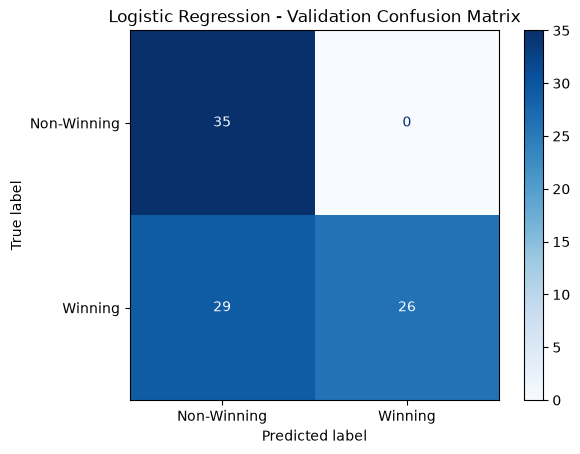

In [20]:

# confusion matrix compares actual classes with the predicted classes by the model
#TN — True Negative	Correctly predicted non-winning seasons
#FP — False Positive	Incorrectly predicted winning seasons
#FN — False Negative	Incorrectly predicted non-winning seasons
#TP — True Positive	Correctly predicted winning seasons
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred)


print("Confusion Matrix:")
print(cm)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Winning", "Winning"] # object for plotting
)
disp.plot(cmap="Blues") # blue color scale

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()
#[[TN FP]
#[FN TP]
#]

### Logistic Regression Validation Confusion Matrix

The confusion matrix provides a detailed comparison between actual and predicted winning-season labels.

The model correctly identifies 35 non-winning seasons and 26 winning seasons. It produces zero false positives but 29 false negatives.

This indicates that the model is conservative when predicting winning seasons. Although its precision is high, it fails to identify many actual winning seasons, resulting in low recall.

In [21]:
y_val_prob = logistic_model.predict_proba(X_val)[:, 1] # all rows and second column

print("First 10 predicted probabilities:")
print(y_val_prob[:10], 4)

First 10 predicted probabilities:
[3.98353287e-01 1.54813202e-01 6.51024268e-03 6.04362930e-01
 5.29428770e-01 6.45554734e-01 6.93141833e-04 1.43366563e-04
 5.29846732e-01 9.57397836e-01] 4


### Logistic Regression Prediction Probabilities

The predict_proba() method returns the probability of belonging to each class.

The second column is selected because it represents the probability of a winning season, which is class 1.

These probabilities are required for ROC-AUC evaluation and decision-threshold optimization. Unlike predicted labels, probabilities provide information about the model's confidence.

The output displays the winning-season probabilities for the first ten validation records.

Logistic Regression ROC-AUC: 0.9371


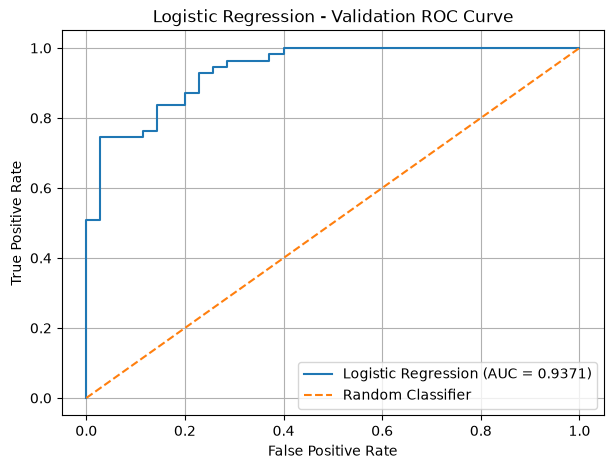

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_val, y_val_prob) # shows the model performance on differnet threshold


auc = roc_auc_score(y_val, y_val_prob) # measures how well the model separates class 1 from class 0 using predicted probabilities

print("Logistic Regression ROC-AUC:", round(auc, 4))

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - Validation ROC Curve")
plt.legend() # displays label
plt.grid(True)
plt.show()

### Logistic Regression — ROC Curve Interpretation

The Logistic Regression model achieved a validation ROC-AUC score of **0.9371 (93.71%)**, indicating excellent discrimination between winning and non-winning hockey seasons.

The ROC curve remains significantly above the random-classifier diagonal and approaches the top-left region, demonstrating strong classification capability across different probability thresholds.

Although the model achieved only 67.78% accuracy and 47.27% recall at the default classification threshold of 0.5, its high ROC-AUC indicates that it generally assigns higher winning probabilities to actual winning seasons than to non-winning seasons.

This suggests that classification threshold selection may improve the balance between false positives and false negatives.

## Classification Model 2: Decision Tree Classifier

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
#  Decision Tree is a machine learning algorithm that makes predictions using a series of if–else decisions
tree_model = Pipeline([ # Decision Tree pipeline

    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=12
    ))
])

tree_model.fit(X_dev, y_dev)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


### Decision Tree Model Training

The Decision Tree classifier makes predictions using a series of feature-based decisions.

The preprocessing pipeline is combined with the classifier to ensure consistent data preparation.

The maximum tree depth is limited to 5 to reduce overfitting, and random_state is set to 12 for reproducibility.

The model is trained on the development dataset. The output confirms that training was completed successfully.

In [24]:
tree_val_pred = tree_model.predict(X_val)
tree_val_prob = tree_model.predict_proba(X_val)[:, 1]

print("First 10 actual values:")
print(y_val.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(tree_val_pred[:10])

First 10 actual values:
[1 1 0 1 1 1 0 0 1 1]

First 10 predicted values:
[0 0 0 1 0 1 0 0 0 1]


### Decision Tree Validation Predictions

The trained Decision Tree model generates predicted class labels and winning-season probabilities for the validation dataset.

The first ten actual and predicted labels are displayed to inspect the model's initial predictions.

Six out of the first ten predictions are correct. The model incorrectly classifies four winning seasons as non-winning seasons.

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


tree_accuracy = accuracy_score(y_val, tree_val_pred)
tree_precision = precision_score(y_val, tree_val_pred, zero_division=0)
tree_recall = recall_score(y_val, tree_val_pred, zero_division=0)
tree_f1 = f1_score(y_val, tree_val_pred, zero_division=0)
tree_auc = roc_auc_score(y_val, tree_val_prob)

print("Decision Tree Validation Results")
print("Accuracy:", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1-score:", round(tree_f1, 4))
print("ROC-AUC:", round(tree_auc, 4))

Decision Tree Validation Results
Accuracy: 0.6778
Precision: 0.9643
Recall: 0.4909
F1-score: 0.6506
ROC-AUC: 0.7873


### Decision Tree — Model Setup

A Decision Tree Classifier was implemented to predict `Team_Status`, indicating whether a hockey team achieved a winning season.

The model was incorporated into a Scikit-Learn Pipeline containing the previously defined preprocessing operations.

A maximum tree depth of five was initially selected to limit model complexity and reduce the risk of overfitting. The random seed was set to 12 for reproducibility.

The model was trained using historical seasons from 1990–2004 and evaluated on the chronological validation period of 2005–2007.

Accuracy, precision, recall, F1-score, and ROC-AUC were calculated to assess classification performance and compare the Decision Tree against Logistic Regression.

Decision Tree Confusion Matrix:
[[34  1]
 [28 27]]


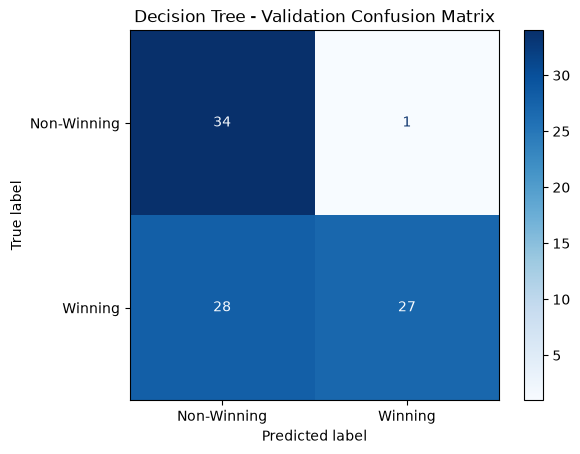

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tree_cm = confusion_matrix(y_val, tree_val_pred)

print("Decision Tree Confusion Matrix:")
print(tree_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=tree_cm,
    display_labels=["Non-Winning", "Winning"]
)

disp.plot(cmap="Blues")
plt.title("Decision Tree - Validation Confusion Matrix")
plt.show()

### Decision Tree Validation Confusion Matrix

The confusion matrix is used to identify the types of classification errors made by the Decision Tree.

The model correctly predicts 34 non-winning seasons and 27 winning seasons.

It produces 1 false positive and 28 false negatives.

Compared with Logistic Regression, the Decision Tree identifies one additional winning season but also incorrectly classifies one non-winning season.

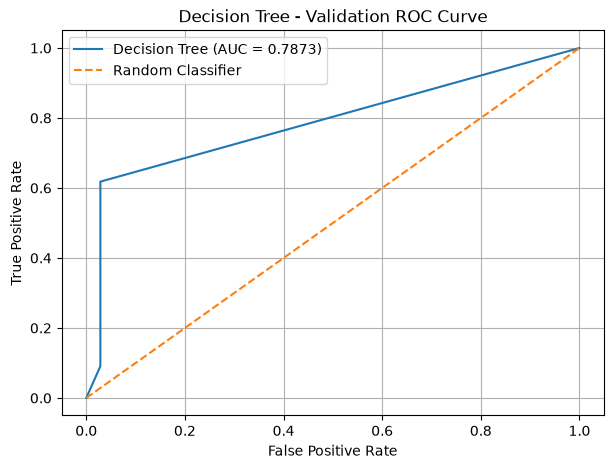

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score


tree_fpr, tree_tpr, tree_thresholds = roc_curve(y_val, tree_val_prob)


plt.figure(figsize=(7, 5))

plt.plot(
    tree_fpr,
    tree_tpr,
    label=f"Decision Tree (AUC = {tree_auc:.4f})"
)

plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree - Validation ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

### Decision Tree — Validation Results and Interpretation

The Decision Tree Classifier was evaluated using 90 validation records from 2005–2007.

The model achieved an accuracy of **67.78%**, precision of **96.43%**, recall of **49.09%**, F1-score of **65.06%**, and ROC-AUC of **78.73%**.

Compared with Logistic Regression, Decision Tree achieved the same accuracy, slightly higher recall and F1-score, but lower precision and substantially lower ROC-AUC.

These results indicate that the Decision Tree correctly identifies slightly more winning seasons at the default threshold, while Logistic Regression demonstrates stronger overall discrimination across classification thresholds.


## Classification Model 3: Random Forest Classifier

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_model = Pipeline([ # random Forest is a machine learning algorithm that combines multiple Decision Trees to make a prediction
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=12
    ))
])


rf_model.fit(X_dev, y_dev)

print("Random Forest trained successfully")

Random Forest trained successfully


### Random Forest Model Training

Random Forest is an ensemble learning algorithm that combines multiple decision trees to generate predictions.

The model uses 100 decision trees, each limited to a maximum depth of 5 to control model complexity and reduce overfitting.

The random seed is set to 12 to ensure reproducibility.

The preprocessing pipeline and classifier are trained together using the development dataset. The output confirms successful model training.

In [29]:

rf_val_pred = rf_model.predict(X_val)

rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

print("First 10 actual values:")
print(y_val.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(rf_val_pred[:10])

print("\nFirst 10 winning probabilities:")
print(rf_val_prob[:10])

First 10 actual values:
[1 1 0 1 1 1 0 0 1 1]

First 10 predicted values:
[0 0 0 0 0 1 0 0 0 1]

First 10 winning probabilities:
[0.20166935 0.16369564 0.08368232 0.41456071 0.19167002 0.51927966
 0.06901424 0.07395661 0.40143765 0.6818061 ]


### Random Forest Validation Predictions

The trained Random Forest model predicts class labels and winning-season probabilities for the validation dataset.

The first ten actual labels, predicted labels and probabilities are displayed.

The model correctly classifies five of the first ten records. Several actual winning seasons receive probabilities below the default threshold of 0.50 and are therefore classified as non-winning seasons.

This suggests that the model is conservative in identifying winning seasons at the default threshold.

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_val, rf_val_pred)

rf_precision = precision_score(y_val, rf_val_pred, zero_division=0)
rf_recall = recall_score(y_val, rf_val_pred, zero_division=0)
rf_f1 = f1_score(y_val, rf_val_pred, zero_division=0)
rf_auc = roc_auc_score(y_val, rf_val_prob)

print("Random Forest Validation Results")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_auc, 4))

Random Forest Validation Results
Accuracy: 0.5556
Precision: 1.0
Recall: 0.2727
F1-score: 0.4286
ROC-AUC: 0.9161


### Random Forest Validation Performance

The Random Forest model is evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC.

The model achieves:

- Accuracy: 0.5556
- Precision: 1.0000
- Recall: 0.2727
- F1-score: 0.4286
- ROC-AUC: 0.9161

The perfect precision indicates that all predicted winning seasons are correct. However, the low recall shows that many actual winning seasons are missed.

Despite its low accuracy at the default threshold, the high ROC-AUC indicates that the model has a good ability to distinguish between the two classes.

Random Forest Confusion Matrix:
[[35  0]
 [40 15]]


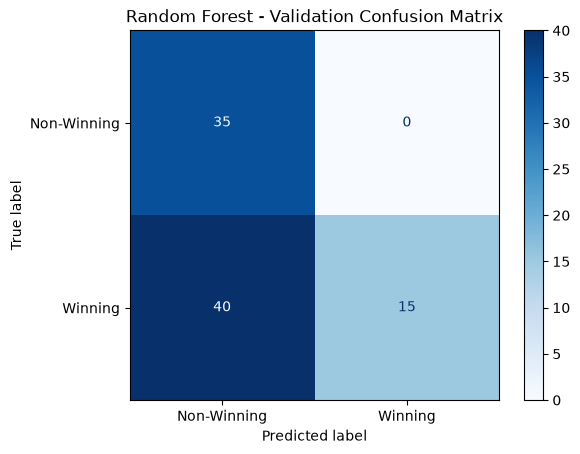

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


rf_cm = confusion_matrix(y_val, rf_val_pred)

print("Random Forest Confusion Matrix:")
print(rf_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Non-Winning", "Winning"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Validation Confusion Matrix")
plt.show()

### Random Forest — Model Setup and Evaluation

A Random Forest Classifier was implemented as the third classification model for predicting `Team_Status`.

Random Forest combines predictions from multiple Decision Trees, which can improve generalization compared with an individual tree.

The model was configured with 100 trees (`n_estimators=100`), a maximum depth of five (`max_depth=5`), and a fixed random seed of 12 for reproducibility.

A Scikit-Learn Pipeline was used to perform preprocessing and classification together. The model was trained using the 372 development observations from 1990–2004 and evaluated on the 90 validation observations from 2005–2007.

Accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC were used to evaluate performance.


### Random Forest — Confusion Matrix Interpretation

The Random Forest Classifier was evaluated on 90 validation observations from 2005–2007.

The confusion matrix produced 35 True Negatives, 15 True Positives, 0 False Positives, and 40 False Negatives.

The model achieved an accuracy of **55.56%**, precision of **100%**, recall of **27.27%**, and F1-score of **42.86%**.

Although the model produced no false positives, it incorrectly classified 40 actual winning seasons as non-winning. This indicates that the model is overly conservative when predicting the positive class.

Compared with Logistic Regression and Decision Tree, Random Forest demonstrated lower accuracy, recall, and F1-score under the initial model configuration.

The ROC-AUC score will be used to further evaluate its ability to distinguish winning and non-winning seasons across different classification thresholds.

### Random Forest — Results and Comparison

The Random Forest Classifier achieved 55.56% accuracy, 100% precision, 27.27% recall, 42.86% F1-score, and a ROC-AUC of 0.9161 on the 2005–2007 validation dataset.

The high ROC-AUC indicates strong discrimination between winning and non-winning seasons across different classification thresholds.

However, the low recall demonstrates that the default 0.5 classification threshold fails to identify many actual winning seasons.

Among the three classifiers, Logistic Regression achieved the highest ROC-AUC (0.9371), followed by Random Forest (0.9161) and Decision Tree (0.7873).

Decision Tree achieved the highest F1-score (0.6506), slightly exceeding Logistic Regression (0.6420).

These findings suggest that Logistic Regression is the strongest overall candidate based on discrimination performance, while classification thresholds may need further evaluation to improve recall.

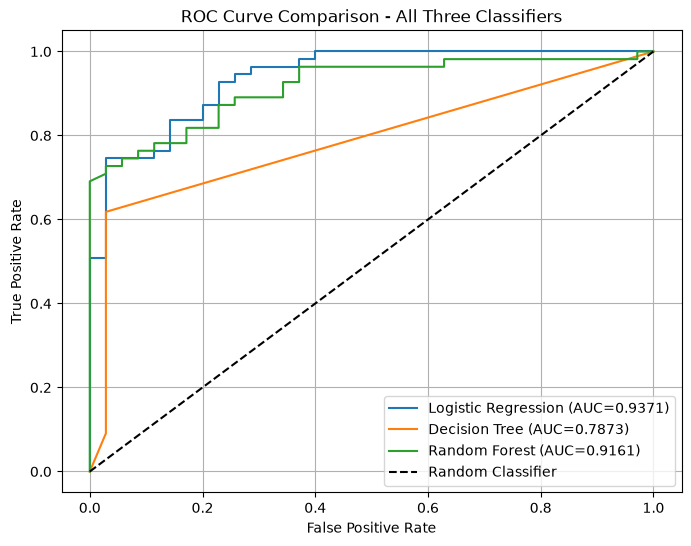

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

lr_fpr, lr_tpr, _ = roc_curve(y_val, y_val_prob)
dt_fpr, dt_tpr, _ = roc_curve(y_val, tree_val_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_val, rf_val_prob)

plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr,
         label=f"Logistic Regression (AUC={auc:.4f})")

plt.plot(dt_fpr, dt_tpr,
         label=f"Decision Tree (AUC={tree_auc:.4f})")

plt.plot(rf_fpr, rf_tpr,
         label=f"Random Forest (AUC={rf_auc:.4f})")


plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - All Three Classifiers")
plt.legend()
plt.grid(True)
plt.show()

## Classification Model Comparison

In [33]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [accuracy, tree_accuracy, rf_accuracy],
    "Precision": [precision, tree_precision, rf_precision],
    "Recall": [recall, tree_recall, rf_recall],
    "F1-score": [f1, tree_f1, rf_f1],
    "ROC-AUC": [auc, tree_auc, rf_auc]
})

print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.6778     1.0000  0.4727    0.6420   0.9371
      Decision Tree    0.6778     0.9643  0.4909    0.6506   0.7873
      Random Forest    0.5556     1.0000  0.2727    0.4286   0.9161


### Validation Model Comparison

The evaluation metrics of Logistic Regression, Decision Tree and Random Forest are combined into a single table to compare their validation performance.

Logistic Regression and Decision Tree achieve the same accuracy of 67.78%.

Decision Tree achieves the highest F1-score of 0.6506, while Logistic Regression achieves the highest ROC-AUC of 0.9371.

Random Forest achieves a strong ROC-AUC of 0.9161 but has the lowest recall at the default classification threshold.

These results suggest that threshold optimization may improve the balance between precision and recall.

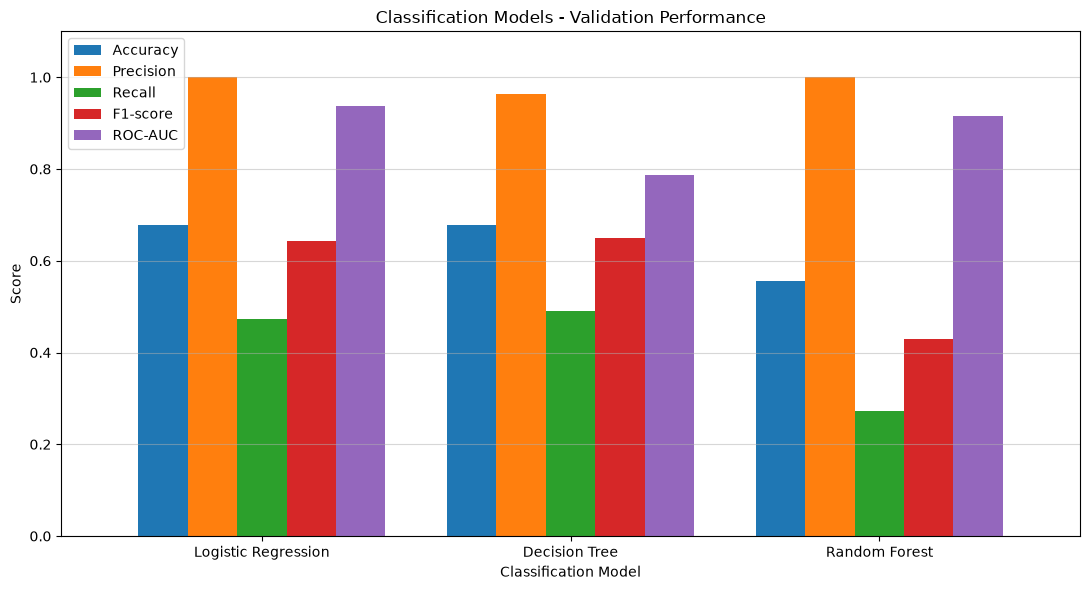

In [34]:
import matplotlib.pyplot as plt

#  model names as  index
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Classification Models - Validation Performance")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0) # x labels rotation
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.5)
plt.tight_layout()
plt.show()

### Classification Model Comparison — Interpretation

Three classification models were trained using 372 development observations from 1990–2004 and evaluated on 90 validation observations from 2005–2007.

Logistic Regression achieved the highest ROC-AUC of 0.9371, indicating the strongest ability to distinguish winning and non-winning seasons across different classification thresholds.

Decision Tree achieved the highest F1-score of 0.6506 and slightly higher recall than Logistic Regression at the default threshold of 0.5.

Random Forest achieved a high ROC-AUC of 0.9161 but lower accuracy, recall, and F1-score under its initial configuration.

The results suggest that Logistic Regression is the strongest initial candidate for further evaluation. However, the relatively low recall of all three models indicates that threshold selection and model configuration may influence classification performance.

The models will be assessed further before final evaluation on the held-out test dataset.

## Logistic Regression — Classification Threshold Tuning

In [35]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

thresholds_to_try = np.arange(0.20, 0.81, 0.05)

results = []

for threshold in thresholds_to_try:

    predictions = (y_val_prob >= threshold).astype(int)  #converts predicted probabilities into classes(0 or 1)

    results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0)
    })

# comparison table
threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))

 Threshold  Accuracy  Precision  Recall  F1-score
      0.20    0.8333     0.9762  0.7455    0.8454
      0.25    0.8111     0.9750  0.7091    0.8211
      0.30    0.7667     0.9722  0.6364    0.7692
      0.35    0.7333     0.9697  0.5818    0.7273
      0.40    0.6889     0.9655  0.5091    0.6667
      0.45    0.6778     1.0000  0.4727    0.6420
      0.50    0.6778     1.0000  0.4727    0.6420
      0.55    0.6444     1.0000  0.4182    0.5897
      0.60    0.6333     1.0000  0.4000    0.5714
      0.65    0.6000     1.0000  0.3455    0.5135
      0.70    0.5889     1.0000  0.3273    0.4932
      0.75    0.5778     1.0000  0.3091    0.4722
      0.80    0.5667     1.0000  0.2909    0.4507


### Classification Threshold Optimization

The default classification threshold of 0.50 may not provide the best balance between precision and recall.

Different thresholds from 0.20 to 0.80 are tested using the Logistic Regression validation probabilities.

For each threshold, Accuracy, Precision, Recall and F1-score are calculated.

Among the tested thresholds, 0.20 produces the highest F1-score of 0.8454 and an accuracy of 83.33%.

Compared with the default threshold, recall increases from 0.4727 to 0.7455 while precision remains high at 0.9762.

Threshold selection is performed using validation data rather than testing data to prevent test-data leakage.

In [36]:
# chosing threshold based on f1-score cuz of the balance bw recall and prescision
best_index = threshold_results["F1-score"].idxmax()
best_threshold = float(threshold_results.loc[best_index, "Threshold"])

print("Selected threshold:", best_threshold)

Selected threshold: 0.2


### Logistic Regression — Threshold Tuning Results

Classification thresholds ranging from 0.20 to 0.80 were evaluated using the chronological validation dataset (2005–2007).

The highest validation F1-score was obtained at a threshold of **0.20**.

At the default threshold of 0.50, Logistic Regression achieved 67.78% accuracy, 100% precision, 47.27% recall, and a 64.20% F1-score.

After selecting the threshold of 0.20, validation accuracy increased to **83.33%**, recall increased to **74.55%**, and F1-score increased to **84.54%**, while precision decreased slightly to **97.62%**.

This indicates that lowering the classification threshold improved the model's ability to identify winning seasons.

The ROC-AUC remained unchanged at 0.9371 because changing the classification threshold does not alter the underlying predicted probabilities.

The threshold of 0.20 was selected as the best candidate within the evaluated range. The final test dataset was not used during threshold selection.

## Advanced Technique 2: Pythagorean Expectation

In [37]:
# PE=GF^2/GF^2+GA^2
import numpy as np
from sklearn.preprocessing import FunctionTransformer

def add_pythagorean(X):
    gf = X[:, 1]
    ga = X[:, 2]

    pyth = gf**2 / (gf**2 + ga**2)

    return np.column_stack((X, pyth)) # adds the calculated pe values as a new column

### Pythagorean Expectation Feature

Pythagorean Expectation is a domain-specific formula used to estimate a team's expected winning proportion based on goals scored and goals conceded.

The formula is:

$$
PE = \frac{GF^2}{GF^2 + GA^2}
$$

A higher value indicates that a team scores more goals relative to the goals it concedes.

The function calculates this value for each record and appends it as an additional numerical feature.

The purpose is to provide the model with a meaningful relationship between GF and GA rather than relying only on their individual values.

This cell defines the transformation function, so no output is displayed.

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_cols = ["Year", "GF", "GA", "+/-"]

numeric_pipeline_pyth = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("pythagorean", FunctionTransformer(add_pythagorean)),
    ("scaler", StandardScaler())
])

preprocessor_pyth = ColumnTransformer([ ("categorical", OneHotEncoder(handle_unknown="ignore"),["Team Name"]),("numerical",
     numeric_pipeline_pyth,
     numeric_cols)
])

### Preprocessing with Pythagorean Expectation

A new numerical preprocessing pipeline is created with three steps:

1. Median imputation to handle missing numerical values.
2. Pythagorean Expectation calculation using FunctionTransformer.
3. Standard scaling of the numerical features.

Imputation is performed before feature engineering so that missing GF or GA values do not prevent the calculation.

One-Hot Encoding is applied separately to Team Name.

Keeping these operations inside the pipeline ensures consistent preprocessing and prevents data leakage when the pipeline is fitted on training data.

This cell defines the updated preprocessing pipeline without fitting it, so no numerical output is produced.

In [39]:
from sklearn.linear_model import LogisticRegression
logistic_pyth = Pipeline([
    ("preprocessor", preprocessor_pyth),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_pyth.fit(X_dev, y_dev)
# trained preprocessor
trained_preprocessor = logistic_pyth.named_steps["preprocessor"]

X_dev_pyth_processed = trained_preprocessor.transform(X_dev)
print(X_dev_pyth_processed.shape)

(372, 39)


### Training Logistic Regression with Feature Engineering

Logistic Regression is trained using the updated preprocessing pipeline containing the Pythagorean Expectation feature.

The pipeline learns the preprocessing parameters from the development dataset only.

The transformed development dataset has a shape of (372, 39), meaning it contains 372 records and 39 processed features.

This confirms that the additional feature has been successfully included in the model input.

In [40]:
from sklearn.base import clone

baseline_preprocessor = clone(preprocessor)
X_dev_original_processed = baseline_preprocessor.fit_transform(X_dev)

print("Original features:", X_dev_original_processed.shape[1])
print("With Pythagorean:", X_dev_pyth_processed.shape[1])

Original features: 38
With Pythagorean: 39


### Before-and-After Feature Engineering Comparison

The original preprocessing pipeline is fitted on the development dataset to determine the number of processed features before feature engineering.

The original dataset contains 38 processed features, while the updated dataset contains 39 features.

The increase of one feature confirms the successful addition of Pythagorean Expectation.

This comparison demonstrates that the advanced technique directly changes the model's input features. Its predictive usefulness is assessed separately using validation metrics.

In [41]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import pandas as pd

original_prob = logistic_model.predict_proba(X_val)[:, 1]
pyth_prob = logistic_pyth.predict_proba(X_val)[:, 1]
threshold = 0.20

original_pred = (original_prob >= threshold).astype(int)
pyth_pred = (pyth_prob >= threshold).astype(int) # marking 1 for probabilities >0.20

def evaluate_model(pred, prob):
    return {
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-score": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob)
    }

comparison_pyth = pd.DataFrame([
    {"Model": "Original", **evaluate_model(original_pred, original_prob)}, # ** dictionary unpacking
    {"Model": "With Pythagorean", **evaluate_model(pyth_pred, pyth_prob)}
])

print(comparison_pyth.round(4).to_string(index=False))

           Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
        Original    0.8333     0.9762  0.7455    0.8454   0.9371
With Pythagorean    0.8333     0.9762  0.7455    0.8454   0.9377


### Pythagorean Expectation — Results and Interpretation

Pythagorean Expectation was implemented as an advanced feature engineering technique using Goals For (GF) and Goals Against (GA).

The engineered feature increased the processed development feature count from 38 to 39.

A controlled comparison was performed using Logistic Regression trained on the 1990–2004 development dataset and evaluated on the 2005–2007 validation dataset. Both models were evaluated using the same classification threshold of 0.20.

The results showed identical accuracy (0.8333), precision (0.9762), recall (0.7455), and F1-score (0.8454).

ROC-AUC increased slightly from 0.9371 to 0.9377.

This suggests that Pythagorean Expectation provided a small improvement in probability ranking but did not improve binary classification at the selected threshold.

A possible explanation is that the original features GF, GA, and goal difference already capture much of the information represented by Pythagorean Expectation.

The experiment demonstrates that adding domain-specific features does not necessarily lead to meaningful improvements in model performance.

## Final Classification Model — Held-Out Test Evaluation

In [42]:
from datetime import datetime
from sklearn.base import clone

#  actual training start time
training_start = datetime.now()

final_model = clone(logistic_model)
final_model.fit(X_train, y_train)


final_tree = clone(tree_model)
final_tree.fit(X_train, y_train)

final_forest = clone(rf_model)
final_forest.fit(X_train, y_train)

# Record training completion time
training_end = datetime.now()

print("Training Started:", training_start)
print("Training Completed:", training_end)
print("All final models trained successfully!")

Training Started: 2026-11-26 14:09:46.208441
Training Completed: 2026-11-26 14:09:46.357940
All final models trained successfully!


### Final Model Training

After completing validation and model selection, fresh copies of Logistic Regression, Decision Tree and Random Forest are created using clone().

All three models are trained on the complete training dataset of 462 records.

This allows the models to learn from both the original development and validation records before final testing.

The training start and completion timestamps are recorded as evidence of model training.

The output confirms that all three final models have been trained successfully. The separate testing dataset remains unused during this training process.

In [43]:
final_test_prob = final_model.predict_proba(X_test)[:, 1]

final_threshold = best_threshold
final_test_pred = (final_test_prob >= final_threshold).astype(int)

print("Final test predictions:", len(final_test_pred))

Final test predictions: 120


### Final Logistic Regression — Test Evaluation

In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Accuracy: Overall percentage of correct predictions
test_accuracy = accuracy_score(y_test, final_test_pred)

# Precision: How many predicted winning seasons were actually winning?
test_precision = precision_score(
    y_test, final_test_pred, zero_division=0
)

# Recall: How many actual winning seasons were identified?
test_recall = recall_score(
    y_test, final_test_pred, zero_division=0
)

# F1-score: Balance between precision and recall
test_f1 = f1_score(
    y_test, final_test_pred, zero_division=0
)

# ROC-AUC: Ability to distinguish winning and non-winning seasons
test_auc = roc_auc_score(y_test, final_test_prob)

print("Final Logistic Regression Test Results")
print("Accuracy:", round(test_accuracy, 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("F1-score:", round(test_f1, 4))
print("ROC-AUC:", round(test_auc, 4))

Final Logistic Regression Test Results
Accuracy: 0.7917
Precision: 0.7253
Recall: 1.0
F1-score: 0.8408
ROC-AUC: 0.9627


### Final Logistic Regression Test Performance

The final Logistic Regression model is evaluated on the unseen testing dataset using the selected classification threshold.

The model achieves:

- Accuracy: 79.17%
- Precision: 72.53%
- Recall: 100.00%
- F1-score: 0.8408
- ROC-AUC: 0.9627

The perfect recall indicates that every actual winning season in the testing dataset is correctly identified.

However, the lower precision indicates that some non-winning seasons are incorrectly classified as winning seasons.

The high ROC-AUC demonstrates a strong ability to distinguish between winning and non-winning seasons.

These results demonstrate the trade-off between identifying more winning seasons and producing additional false positives.

Final Test Confusion Matrix:
[[29 25]
 [ 0 66]]


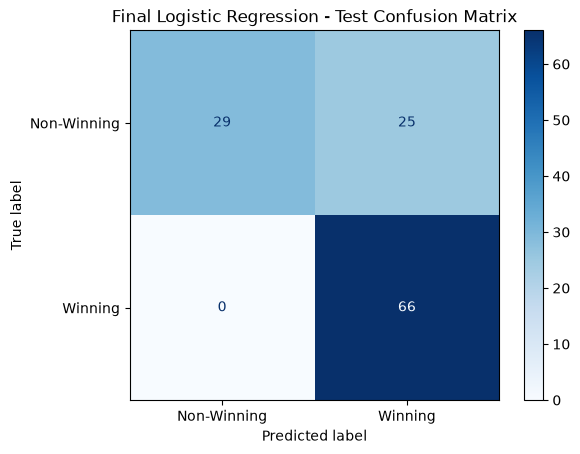

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
test_cm = confusion_matrix(
    y_test, final_test_pred, labels=[0, 1]
)

print("Final Test Confusion Matrix:")
print(test_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Non-Winning", "Winning"]
)

disp.plot(cmap="Blues")

plt.title("Final Logistic Regression - Test Confusion Matrix")
plt.show()

### Final Logistic Regression — Test Results and Interpretation

The final Logistic Regression model was trained on 462 historical team-season observations from 1990–2007 and evaluated on 120 unseen observations from 2008–2011.

Using the classification threshold of 0.20 selected during validation, the model achieved:

- Accuracy: 79.17%
- Precision: 72.53%
- Recall: 100%
- F1-score: 84.08%
- ROC-AUC: 0.9627

The confusion matrix showed 29 true negatives, 25 false positives, 0 false negatives, and 66 true positives.

The model correctly identified every actual winning season but incorrectly classified 25 non-winning seasons as winning. This indicates a trade-off between recall and precision caused in part by the relatively low classification threshold.

The high ROC-AUC demonstrates strong discrimination between winning and non-winning seasons across classification thresholds.

These findings apply to classification based on same-season statistics, not genuine preseason forecasting.

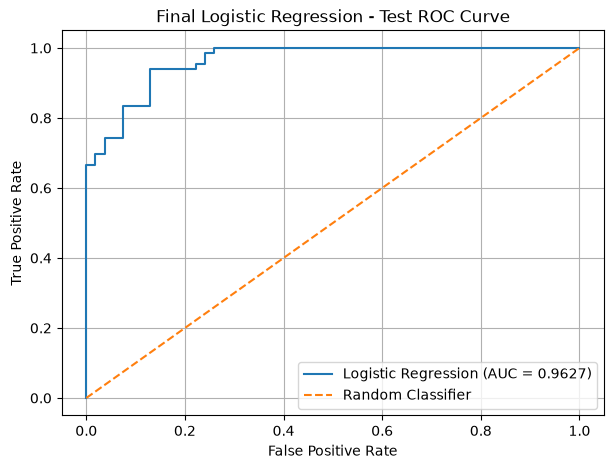

In [46]:
from sklearn.metrics import roc_curve

#  ROC curve using test probabilities
test_fpr, test_tpr, _ = roc_curve(y_test, final_test_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    test_fpr,
    test_tpr,
    label=f"Logistic Regression (AUC = {test_auc:.4f})"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Logistic Regression - Test ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

### Final Classification Evaluation — Methodology

After comparing Logistic Regression, Decision Tree, and Random Forest on the chronological validation dataset (2005–2007), Logistic Regression was selected based on its strong ROC-AUC and validation performance.

A classification threshold of 0.20 was selected using validation F1-score. The selected model was then retrained on the complete training dataset containing 462 historical records from 1990–2007.

The final model was evaluated on 120 previously unseen observations from 2008–2011.

Accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC were used to assess its final classification performance.

The test dataset was not used during model selection, threshold tuning, or preprocessing parameter estimation. The selected model and threshold were fixed before final testing.

In [47]:
from sklearn.base import clone

final_tree = clone(tree_model)
final_tree.fit(X_train, y_train)
final_forest = clone(rf_model)
final_forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Team Name','Year','GF','GA','+/-']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns 

### Final Decision Tree and Random Forest Training

Fresh copies of the Decision Tree and Random Forest pipelines are trained using the complete training dataset.

The preprocessing parameters and classifier parameters are learned from training data only.

The displayed pipeline representation confirms that preprocessing and classification are combined into a single model workflow.

These trained models are used for evaluation on the unseen testing dataset.

In [48]:
tree_test_prob = final_tree.predict_proba(X_test)[:, 1]
forest_test_prob = final_forest.predict_proba(X_test)[:, 1]

#  default threshold  0.50
tree_test_pred = (tree_test_prob >= 0.50).astype(int)
forest_test_pred = (forest_test_prob >= 0.50).astype(int)

print("Decision Tree predictions:", len(tree_test_pred))
print("Random Forest predictions:", len(forest_test_pred))

Decision Tree predictions: 120
Random Forest predictions: 120


### Decision Tree and Random Forest Test Predictions

The trained Decision Tree and Random Forest models generate winning-season probabilities for the unseen testing dataset.

A classification threshold of 0.50 is applied to convert probabilities into binary class labels.

Probabilities are retained for ROC-AUC evaluation, while class labels are used to calculate Accuracy, Precision, Recall and F1-score.

The output confirms that each model generates 120 predictions, corresponding to all 120 testing records.

In [49]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import pandas as pd

def evaluate_test(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

final_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        **evaluate_test(y_test, final_test_pred, final_test_prob)
    },
    {
        "Model": "Decision Tree",
        **evaluate_test(y_test, tree_test_pred, tree_test_prob)
    },
    {
        "Model": "Random Forest",
        **evaluate_test(y_test, forest_test_pred, forest_test_prob)
    }
])

print(final_comparison.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.7917     0.7253  1.0000    0.8408   0.9627
      Decision Tree    0.8250     0.8082  0.8939    0.8489   0.8558
      Random Forest    0.8500     0.9444  0.7727    0.8500   0.9517


### Final Classification Model Comparison

The three classification models were retrained using the complete
training dataset containing 462 records from 1990–2007.

All models were evaluated on the same held-out test dataset
containing 120 records from 2008–2011.

Logistic Regression used the classification threshold of 0.20 selected during validation. Decision Tree and Random Forest used the default threshold of 0.50.
Accuracy, Precision, Recall, F1-score, and ROC-AUC were calculated to compare their performance on unseen records.
The test results are reported for comparison. The original model selection was based on validation performance rather than the held-out test results.

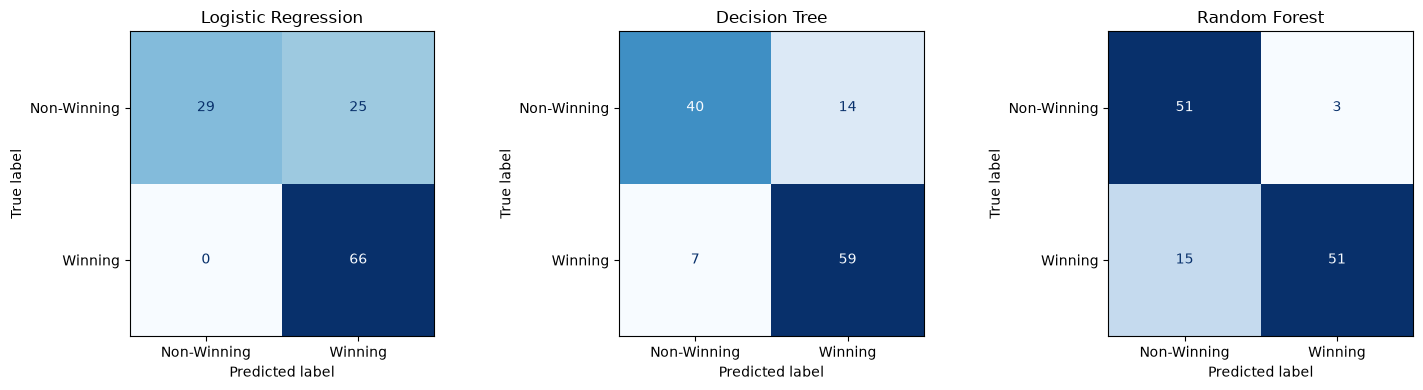

In [50]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

models = [
    ("Logistic Regression", final_test_pred),
    ("Decision Tree", tree_test_pred),
    ("Random Forest", forest_test_pred)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Non-Winning", "Winning"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Final Test Confusion Matrix Comparison

The confusion matrices of all three classification models are displayed side by side.

This visualization helps compare correct predictions, false positives and false negatives across the models.

Logistic Regression:

- True Negatives: 29
- False Positives: 25
- False Negatives: 0
- True Positives: 66

Decision Tree:

- True Negatives: 40
- False Positives: 14
- False Negatives: 7
- True Positives: 59

Random Forest:

- True Negatives: 51
- False Positives: 3
- False Negatives: 15
- True Positives: 51

Logistic Regression achieves the highest recall because it identifies all winning seasons.

Random Forest produces the fewest false positives and achieves the highest overall accuracy.

Decision Tree provides a balance between identifying winning seasons and avoiding incorrect positive predictions.

The appropriate model depends on whether identifying all winning seasons or reducing incorrect winning-season predictions is more important.

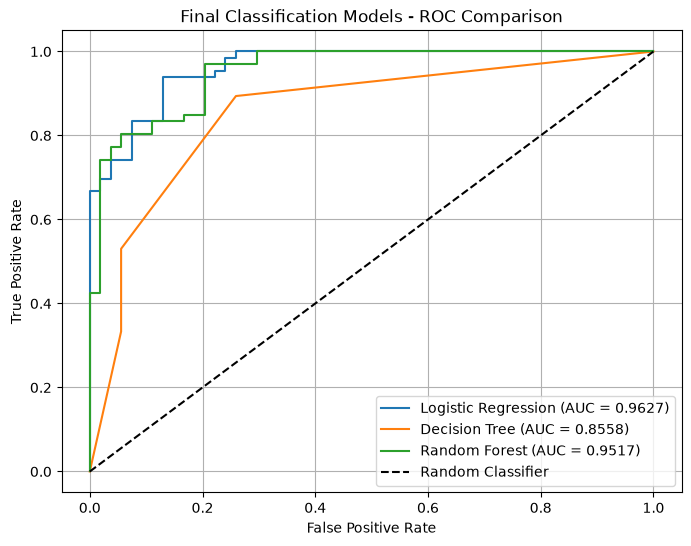

In [51]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

models = [
    ("Logistic Regression", final_test_prob),
    ("Decision Tree", tree_test_prob),
    ("Random Forest", forest_test_prob)
]

for name, probabilities in models:
    fpr, tpr, _ = roc_curve(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc_score(y_test, probabilities):.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Classification Models - ROC Comparison")
plt.legend()
plt.grid(True)
plt.show()

### Final Classification Model Comparison — Interpretation

All three classification models were retrained using 462 historical observations from 1990–2007 and evaluated on the untouched test dataset containing 120 observations from 2008–2011.

Random Forest achieved the highest test accuracy (85.00%), precision (94.44%), and F1-score (0.8500).

Logistic Regression achieved the highest recall (100%) and ROC-AUC (0.9627). Its recall indicates that all actual winning seasons were correctly identified, although some non-winning seasons were incorrectly predicted as winning.

Decision Tree achieved 82.50% accuracy, with precision of 0.8082 and recall of 0.8939.

Although Random Forest achieved the highest test accuracy, Logistic Regression remains the model selected during validation. The final test results are reported as an independent evaluation rather than being used for additional model selection.

The results demonstrate that model performance depends on the evaluation metric and the balance between false positives and false negatives.

## Final Model Training Log

In [52]:
from datetime import datetime

SEED = 12
training_start_time = training_start.strftime("%Y-%m-%d %H:%M:%S")
training_end_time = training_end.strftime("%Y-%m-%d %H:%M:%S")

print("=" * 60)
print("HOCKEY TEAM PERFORMANCE - CLASSIFICATION TRAINING LOG")
print("=" * 60)

print("Random Seed:", SEED)
print("Training Started:", training_start_time)
print("Training Completed:", training_end_time)

print("\nDATASET INFORMATION")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Training Years: 1990-2007")
print("Testing Years: 2008-2011")

print("\nFINAL MODEL TEST RESULTS")
print(final_comparison.round(4).to_string(index=False))

print("=" * 60)

HOCKEY TEAM PERFORMANCE - CLASSIFICATION TRAINING LOG
Random Seed: 12
Training Started: 2026-11-26 14:09:46
Training Completed: 2026-11-26 14:09:46

DATASET INFORMATION
Training Records: 462
Testing Records: 120
Training Years: 1990-2007
Testing Years: 2008-2011

FINAL MODEL TEST RESULTS
              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.7917     0.7253  1.0000    0.8408   0.9627
      Decision Tree    0.8250     0.8082  0.8939    0.8489   0.8558
      Random Forest    0.8500     0.9444  0.7727    0.8500   0.9517


### Model Training Log — Explanation

This cell records the final classification experiment information, including the project's random seed, execution timestamp, training and testing dataset sizes, chronological year ranges, and final model evaluation metrics.

The training dataset contains 462 observations from 1990–2007, while the held-out test dataset contains 120 observations from 2008–2011.

Three classification models were evaluated: Logistic Regression, Decision Tree, and Random Forest.

The reported metrics include accuracy, precision, recall, F1-score, and ROC-AUC.

The log provides evidence of the model evaluation performed for the project The displayed timestamp represents when the logging cell was executed.